# MSc Final Project — Visible In-Progress (VIP) notebook

| | |
|---|---|
| **Project title** | Diagnosing Tuberculosis in Chest X-rays from Two Countries: A Cross-Dataset Study of Generalisation, Lung Masking and Simple Corrections on the Montgomery and Shenzhen Sets |
| **Student name / number** | Izuchukwu D. Agballah, 24136661 |
| **Supervisor** | Muhammad Yaqoob |
| **GitHub repository** | https://github.com/Izuchukwu-A/msc-project-agballah |
| **Overleaf project** | *link to your IPR/FPR Overleaf project* |
| **Ethics approval** | Not required — both datasets are public, de-identified releases from the US National Library of Medicine (no new data collection, no personal data) |

This notebook is my **practical work**: data, artefact, experiments and results. The **report** (IPR 10%, FPR 70%) is written in the Overleaf template. The **demo/viva (20%)** is run from this notebook.

**How this notebook is organised.** The engineering lives in a small package, `tbx` (`src/tbx/`), driven by numbered CLI scripts (`scripts/00`–`08`) and one YAML file per experiment (`configs/`). The rule from the methodology is that the *direction* of an experiment (which set trains, which tests) and the *image region* (whole / lung-cropped / lung-masked) are settings in a config, never code edits — so one pipeline runs every experiment. Each section below runs the relevant script and then shows what it produced.

**Order of work — status at week 9.** Sections follow the build order week by week:

| Phase | Weeks | Work | Status |
|---|---|---|---|
| 2 | 3–4 | Data prep, metadata, frozen 5-fold splits | ✅ done |
| 3 | 4–5 | EDA / shortcut audit, lung U-Net masks | ✅ done |
| 4 | 5–7 | Classical lung-field baseline, within-set CNN | ✅ done |
| 5 | 7–8 | Cross-dataset generalisation, region controls, Grad-CAM audit, DeLong tests | ✅ done |
| 6 | 8–9 | Per-image intensity corrections (histeq / CLAHE / z-score) | ✅ done — CNN Montgomery→Shenzhen in week 8; classical model, Shenzhen→Montgomery direction, DeLong tests and Grad-CAM on CLAHE in week 9 |

### Working method (git)

1. **Supervisor is a collaborator** on the GitHub repo (Settings → Collaborators).
2. **Commit and push after every task and every change.** The history shows how the project developed.
   ```bash
   git status
   git add .
   git commit -m "CODE: what you did"
   git push
   ```
3. Start each commit message with the part worked on: `DATA:` · `CODE:` · `EXP:` · `TEST:` · `RESULT:` · `FIX:`
   e.g. `FIX: no-flip augmentation, AUC up 0.02 on Shenzhen within-set`
4. **Two parts of the artefact are developed on their own branches**: `baseline` (classical lung-field model) and `proposed-method` (the CNN with region controls, cross-dataset evaluation and corrections). See below.
5. **Before each supervision meeting, push the latest work** so the supervisor reviews what changed.

### Working on a branch

A branch lets me build one part without breaking the working version on `main`.

**1. Create a branch and work on it**
```bash
git checkout -b baseline
git add .
git commit -m "CODE: classical lung-field baseline, first version"
git push -u origin baseline
```
**2. When the part works, merge it into `main`**
```bash
git checkout main
git merge baseline
git push
```
**3. Start the next part on a new branch**
```bash
git checkout -b proposed-method
```
`git branch` shows the current branch (marked `*`). On GitHub the supervisor can see every branch and its commits.

# 1. Imports and environment
*Week 1 — project set-up.* Install the package in editable mode, put `tbx` on the path, fix the random seed, and name the folders the scripts read and write.

In [1]:
# One-time: install the package and its dependencies (editable, so src/ edits take effect immediately).
# The [dl] extra adds torch/torchvision/timm/grad-cam for the CNN and U-Net; omit it for the classical path only.
# %pip install -e ".[dl]"

import sys, os
from pathlib import Path

# Find the repo root (the folder holding src/tbx and configs/) whether the notebook is
# opened from the repo itself or from its parent folder, then work from there so
# configs/, data/, outputs/ and scripts/ all resolve.
def _find_repo(start: Path) -> Path:
    for cand in [start, start / "tbx", *start.parents]:
        if (cand / "src" / "tbx" / "config.py").exists() and (cand / "configs").is_dir():
            return cand.resolve()
    raise FileNotFoundError(f"Could not find the tbx repo (src/tbx + configs/) from {start}")

REPO = _find_repo(Path.cwd())
os.chdir(REPO)
for p in (REPO / "src", REPO / "scripts"):      # src = the package, scripts = _bootstrap_path
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
# Drop a stale 'tbx' (e.g. the repo *folder* picked up as an empty namespace package).
for m in [m for m in sys.modules if m == "tbx" or m.startswith("tbx.")]:
    del sys.modules[m]

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

import tbx
from tbx.config import load_config
from tbx.utils import seed_everything
from tbx.utils.io import load_json

seed_everything(42)                           # Python, NumPy and torch seeded together

CFG      = "configs/default.yaml"
OUT      = REPO / "outputs"
PROC     = REPO / "data" / "processed"

# RERUN = False reuses finished results (U-Net weights, feature CSVs, each experiment's
# results.json) so "Run All" finishes in seconds. Set True to recompute everything
# (needs the GPU: about 3-5 minutes per CNN run, roughly 1-2 hours for all of them).
RERUN = False

def step(cmd, done=None):
    """%run a script, unless its output `done` already exists and RERUN is False."""
    if done is not None and not RERUN and Path(done).exists():
        print(f"[skip] {cmd}\n       already done -> {Path(done).relative_to(REPO)}  (set RERUN=True to redo)")
        return
    get_ipython().run_line_magic("run", cmd)

def exp(config):
    """Run one experiment config (skipped if its results.json already exists)."""
    name = load_config(config).name
    step(f"scripts/05_run_experiment.py --config {config}", OUT / name / "results.json")

print("tbx", tbx.__version__, "| repo:", REPO, "| RERUN:", RERUN)

tbx 0.1.0 | repo: C:\Users\harip\OneDrive\Pictures\Derick\tb_cross_dataset_code_week7\tbx | RERUN: False


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: project set-up, package install and environment"
git push
```

# 2. Research question and objectives

**Problem.** Tuberculosis is most often first screened with a chest X-ray, but the countries with the highest TB burden have the fewest radiologists. An automated reader could help, yet a model trained in one hospital often drops sharply when used in another: it can learn the *source* of an image (borders, exposure, framing, prevalence) instead of the disease. This project measures how much of a TB screening result survives a move to a different hospital, how much of the signal sits outside the lungs, and which simple corrections recover what does not transfer.

**Main research question.** How well does a TB chest-X-ray classifier trained on one country's data generalise to another country's data, and how much of its performance depends on signal outside the lung field?

**Sub-questions.**
1. How large is the drop from within-set to cross-dataset evaluation, in each direction (Montgomery→Shenzhen and Shenzhen→Montgomery)?
2. How much does performance fall when the lungs are masked out (`lung_masked`) — i.e. how much signal is outside the lungs?
3. Does restricting the model to the lung field (lung-crop / lung-mask / classical lung-field features) improve cross-dataset transfer?
4. Do per-image intensity corrections (histogram equalisation, CLAHE, z-score) narrow the cross-dataset gap?
5. With only 138 Montgomery images, how wide are the confidence intervals, and which differences survive them?

**Objectives (specific and measurable).**
1. Build one config-driven pipeline where train set, test set, region and model are YAML settings (no code change per experiment).
2. Report AUC with 95% bootstrap CIs (2,000 resamples) for within-set and cross-dataset runs in both directions.
3. Quantify the outside-lung signal with a `lung_masked` control and a Grad-CAM lung-attention ratio.
4. Test whether region restriction and intensity corrections change cross-dataset AUC, using paired DeLong tests with Holm correction.
5. Keep every result reproducible: frozen 5-fold splits, fixed seed, and each experiment's config saved beside its results.

# 3. Data
*FPR: Methodology — Phase 2 (weeks 3–4).*

**Source and licence.** Two public chest-X-ray sets released together by the US National Library of Medicine (Jaeger et al., 2014): **Montgomery County** (138 images: 58 TB, 80 normal; ships radiologist lung masks) and **Shenzhen** (662 images: 336 TB, 326 normal). Free for research use.

**Ethics / GDPR.** Both sets are already de-identified and public; no new data is collected and no personal data is stored, so no ethics approval is required. Images live under `data/raw/` and are **git-ignored** — they are never committed.

`00_download_data.py` fetches both sets into the NLM layout; `01_prepare_data.py` reads the TB label from each filename (`_0` normal, `_1` TB), parses age/sex from the clinical reading files, and writes `metadata.csv` plus the frozen 5-fold splits.

In [2]:
# Phase 2 — build the metadata table and the frozen 5-fold splits.
# (Run scripts/00_download_data.py once first to populate data/raw/.)
%run scripts/01_prepare_data.py --config configs/default.yaml

[metadata] montgomery: 138 images (58 TB, 80 normal)


[metadata] shenzhen: 662 images (336 TB, 326 normal)
[prepare] wrote data/processed/metadata.csv (800 rows)
[splits] wrote data\processed\splits\montgomery_folds.json (5 folds: 28, 28, 28, 27, 27)
[splits] wrote data\processed\splits\shenzhen_folds.json (5 folds: 133, 133, 132, 132, 132)


In [3]:
# What was produced
meta = pd.read_csv(PROC / "metadata.csv")
print("rows:", len(meta))
display(meta.head())
display(meta.groupby(["dataset", "label"]).size().rename("n").reset_index())

rows: 800


,image_id,dataset,label,image_path,left_mask_path,right_mask_path,reading_path,age,sex,finding,width,height
0,MCUCXR_0001_0,montgomery,0,data\raw\MontgomerySet\CXR_png\MCUCXR_0001_0.png,data\raw\MontgomerySet\ManualMask\leftMask\MCU...,data\raw\MontgomerySet\ManualMask\rightMask\MC...,data\raw\MontgomerySet\ClinicalReadings\MCUCXR...,27.0,F,normal,4892,4020
1,MCUCXR_0002_0,montgomery,0,data\raw\MontgomerySet\CXR_png\MCUCXR_0002_0.png,data\raw\MontgomerySet\ManualMask\leftMask\MCU...,data\raw\MontgomerySet\ManualMask\rightMask\MC...,data\raw\MontgomerySet\ClinicalReadings\MCUCXR...,40.0,F,normal,4892,4020
2,MCUCXR_0003_0,montgomery,0,data\raw\MontgomerySet\CXR_png\MCUCXR_0003_0.png,data\raw\MontgomerySet\ManualMask\leftMask\MCU...,data\raw\MontgomerySet\ManualMask\rightMask\MC...,data\raw\MontgomerySet\ClinicalReadings\MCUCXR...,21.0,F,normal,4020,4892
3,MCUCXR_0004_0,montgomery,0,data\raw\MontgomerySet\CXR_png\MCUCXR_0004_0.png,data\raw\MontgomerySet\ManualMask\leftMask\MCU...,data\raw\MontgomerySet\ManualMask\rightMask\MC...,data\raw\MontgomerySet\ClinicalReadings\MCUCXR...,11.0,F,normal,4020,4892
4,MCUCXR_0005_0,montgomery,0,data\raw\MontgomerySet\CXR_png\MCUCXR_0005_0.png,data\raw\MontgomerySet\ManualMask\leftMask\MCU...,data\raw\MontgomerySet\ManualMask\rightMask\MC...,data\raw\MontgomerySet\ClinicalReadings\MCUCXR...,33.0,M,normal,4020,4892


,dataset,label,n
0,montgomery,0,80
1,montgomery,1,58
2,shenzhen,0,326
3,shenzhen,1,336


### Data-quality check and cleaning log

| Step | Problem found | What I changed | Why |
|---|---|---|---|
| 1 | Montgomery is 12-bit, Shenzhen 8-bit | Rescale Montgomery to [0,1] by its bit depth (`data.montgomery_bits`) | Put both sets on one intensity scale |
| 2 | Images are different sizes and aspect ratios | Resize to 224 and **pad to square** (`pad_to_square`), not stretch | Preserve anatomy; stretching distorts the ribcage |
| 3 | Montgomery films carry large black borders; Shenzhen do not | Keep borders but take intensity stats from lung content only | The border is a hospital tell, not a finding |
| 4 | Shenzhen ships no lung masks | Generate them with a U-Net trained on Montgomery (Phase 3) | Needed for the lung-crop / lung-mask region controls |
| 5 | Label only in the filename | Parse last digit of `image_id`; cross-check count against readings | Avoid mislabelling |

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "DATA: metadata table and frozen 5-fold splits, see cleaning log"
git push
```

# 4. Exploratory analysis
*FPR: Methodology; Quality and Results — Phase 3 (weeks 4–5).*

The point of the EDA is the **shortcut audit**: if the two hospitals differ in exposure, framing and border, a model could separate TB from normal partly by recognising the hospital. `02_run_eda.py` writes a side-by-side visual grid, per-set intensity histograms, class/age/sex summaries and `metadata_summary.csv`.

In [4]:
# Phase 3 — EDA and the shortcut audit
%run scripts/02_run_eda.py --config configs/default.yaml

[eda] wrote outputs\eda\metadata_summary.csv


[eda] wrote outputs\eda\visual_audit.png
[eda] wrote outputs\eda\class_balance.png


[eda] wrote outputs\eda\age_distribution.png
[eda] wrote outputs\eda\sex_ratio.png


[eda] wrote outputs\eda\intensity_histogram.png


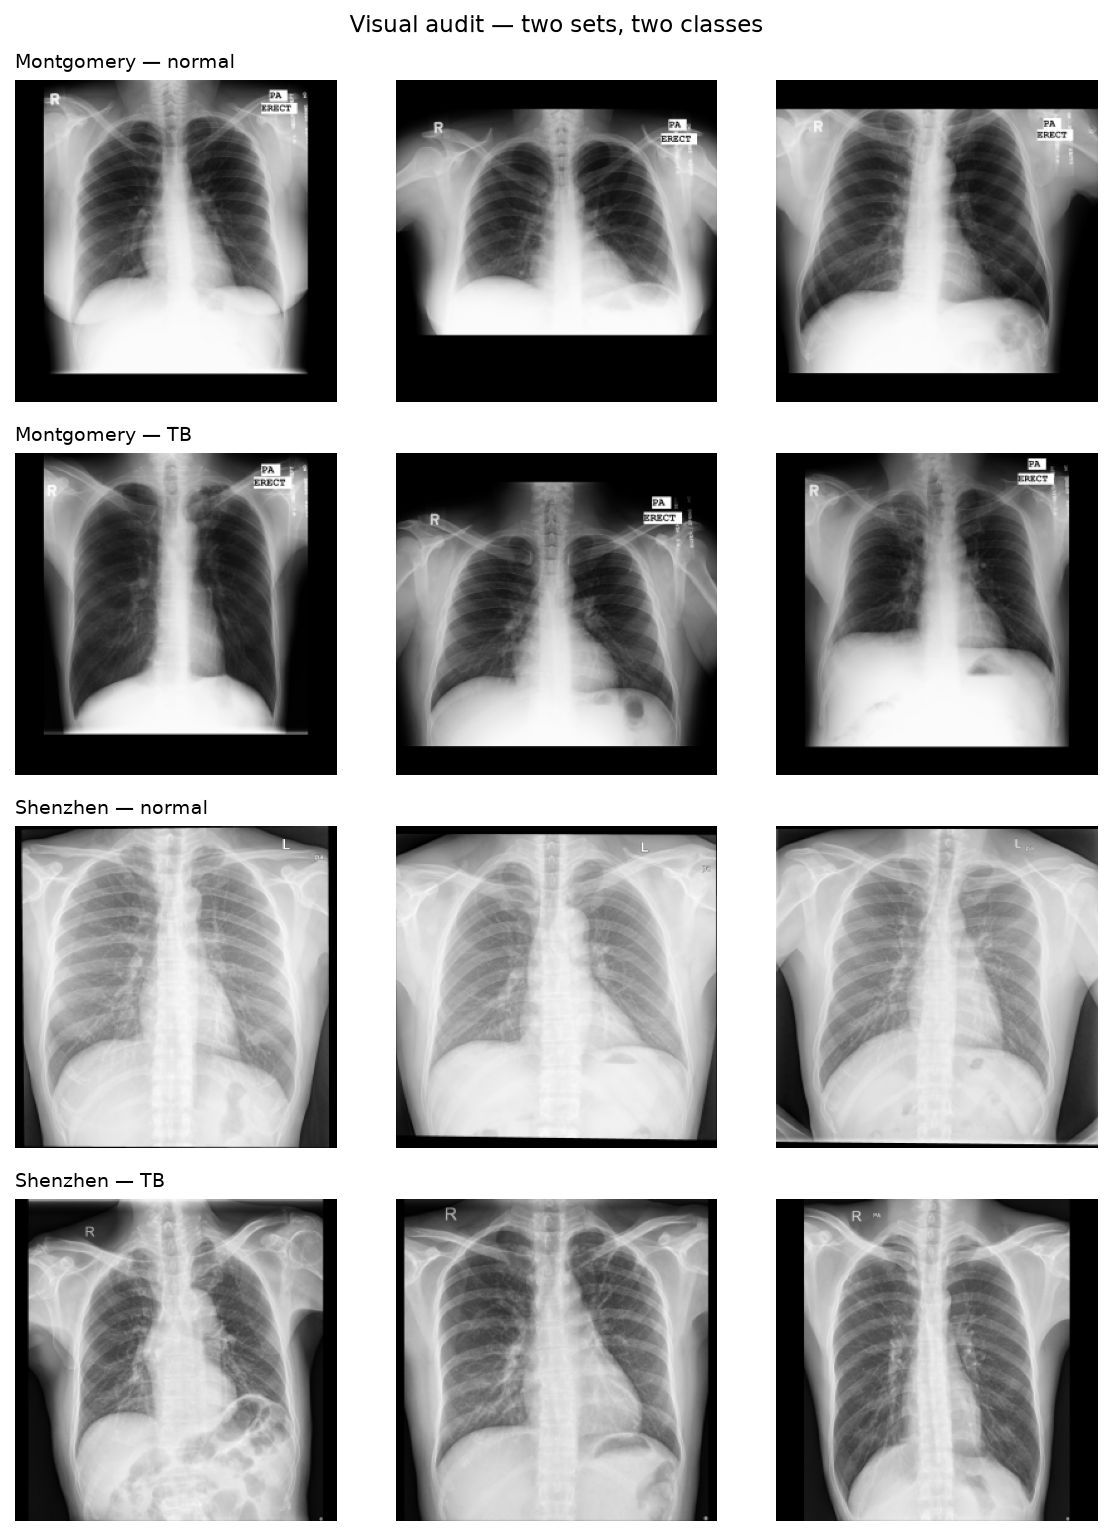

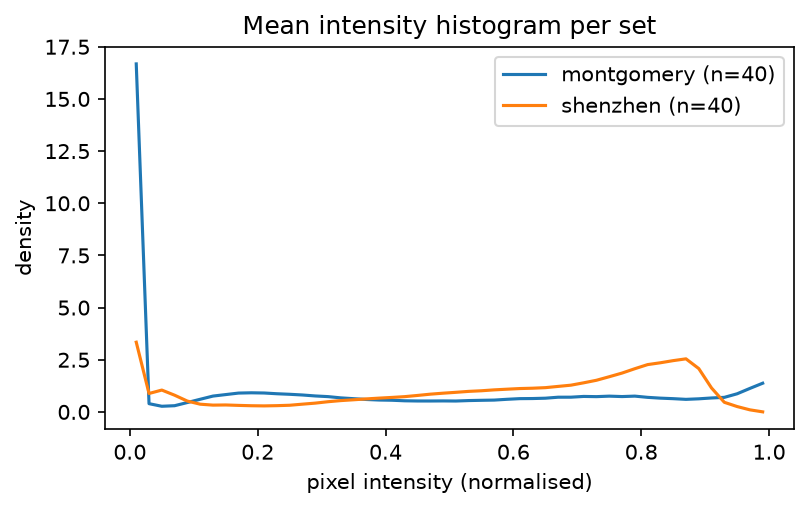

,dataset,class,n,age_mean,age_sd,pct_female,pct_missing_age
0,montgomery,normal,80,34.3,15.4,66.2,0.0
1,montgomery,TB,58,48.1,20.1,36.2,0.0
2,shenzhen,normal,326,33.1,14.3,32.2,0.0
3,shenzhen,TB,336,37.7,15.0,32.1,0.0


In [5]:
eda = OUT / "eda"
display(Image(filename=str(eda / "visual_audit.png")))
display(Image(filename=str(eda / "intensity_histogram.png")))
display(pd.read_csv(eda / "metadata_summary.csv"))

*What did I learn, and how does it affect the method?* The two sets sit at different exposure/contrast ranges and Montgomery's black borders are a clear source-of-image tell. That is exactly the cue a classifier could exploit instead of the disease, which motivates (a) the `lung_masked` control that blanks the lungs to measure outside-lung signal, (b) restricting to the lung field, and (c) the per-image intensity corrections in Phase 6.

### Lung masks (U-Net)
*Phase 3 (weeks 4–5).* Montgomery provides manual masks; Shenzhen does not. A U-Net is trained on Montgomery and used to generate Shenzhen masks, with held-out Dice reported so the region controls only trust masks that are actually good. Needs the `[dl]` extra and ideally a GPU.

[skip] scripts/03_train_unet_masks.py --config configs/default.yaml --epochs 60
       already done -> outputs\segmentation\unet_report.json  (set RERUN=True to redo)
Held-out Montgomery Dice: 0.9743


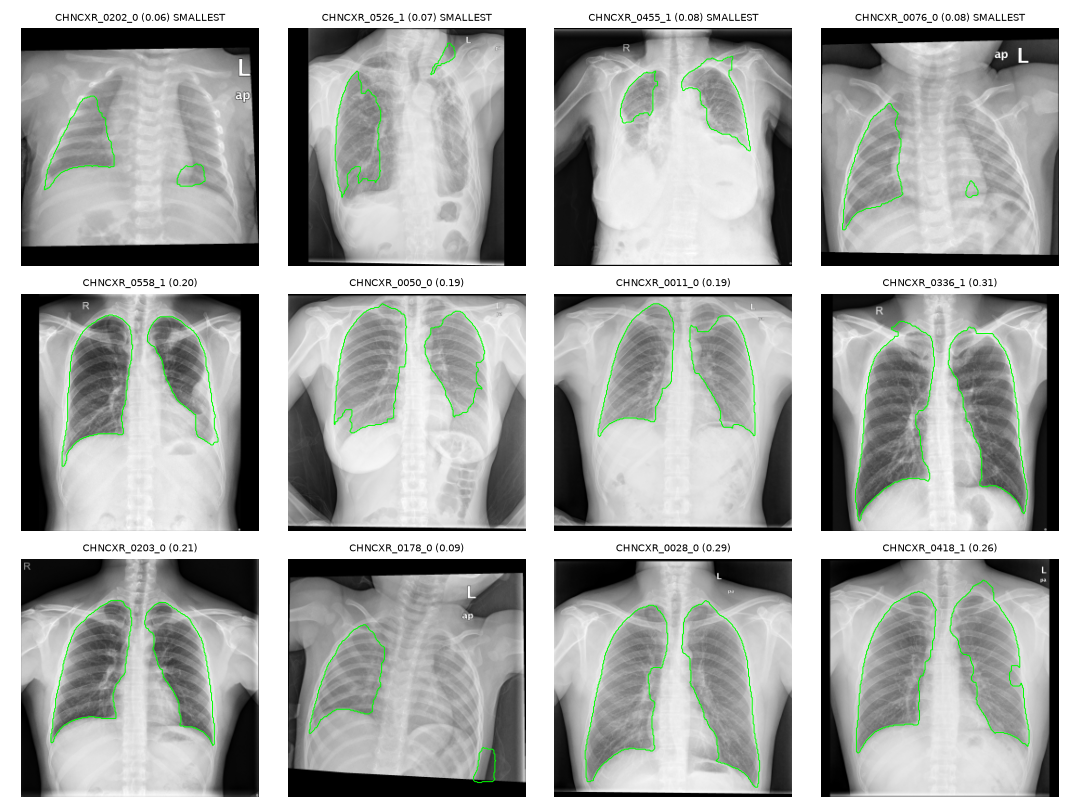

In [6]:
# Phase 3 — train the lung U-Net on Montgomery, generate Shenzhen masks (GPU; skipped if already trained)
step("scripts/03_train_unet_masks.py --config configs/default.yaml --epochs 60",
     OUT / "segmentation" / "unet_report.json")
report = load_json(OUT / "segmentation" / "unet_report.json")
print("Held-out Montgomery Dice:", round(report["val_dice"], 4))
display(Image(filename=str(OUT / "segmentation" / "shenzhen_mask_check.png")))

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: EDA figures, metadata summary and lung-mask U-Net"
git push
```

# 5. Method and artefact
*FPR: Methodology — Phase 4 (weeks 5–7).*

**Why these methods?** Two models are compared on identical folds. The **baseline** is a classical lung-field model: GLCM/LBP/intensity texture features computed *inside the lung mask only*, fed to logistic regression or an RBF SVM — by construction it cannot use the border or anything outside the lungs. The **proposed method** is a CNN (ResNet-18, with DenseNet-121 as a check), which is stronger but free to use the whole image, so it is paired with the region controls and the Grad-CAM audit. Comparing them answers "does the extra CNN capacity buy real lung signal, or shortcut signal?" (literature: Jaeger et al. 2014; Pasa et al. 2019; Zech et al. 2018; Maguolo & Nanni 2021 — see the extraction sheet).

AUC is the primary metric (threshold-free, unaffected by the prevalence gap). Alongside it: sensitivity/specificity at a threshold **fixed on training data**, and specificity at 90% sensitivity as the screening operating point. Every number carries a 95% bootstrap CI.

### Baseline — classical lung-field model
Developed on its own branch: `git checkout -b baseline`. `04_build_features.py` writes one feature row per image (lung field only).

In [7]:
# Phase 4 — lung-field texture/intensity features for the classical baseline
step("scripts/04_build_features.py --config configs/default.yaml", PROC / "features.csv")
feat = pd.read_csv(PROC / "features.csv")
print("features:", feat.shape)
display(feat.head())

[skip] scripts/04_build_features.py --config configs/default.yaml
       already done -> data\processed\features.csv  (set RERUN=True to redo)
features: (800, 54)


,glcm_contrast,glcm_dissimilarity,glcm_homogeneity,glcm_energy,glcm_correlation,glcm_ASM,lbp_0,lbp_1,lbp_2,lbp_3,...,int_bin_12,int_bin_13,int_bin_14,int_bin_15,int_mean,int_std,int_skew,image_id,label,dataset
0,3.466668,1.133487,0.600023,0.100095,0.974168,0.010299,0.017516,0.011216,0.013905,0.012599,...,0.279020,0.122916,0.051625,0.001229,0.318694,0.170159,1.062727,MCUCXR_0001_0,0,montgomery
1,2.726003,1.025975,0.621017,0.100258,0.978201,0.010321,0.020416,0.011119,0.011210,0.010026,...,0.303318,0.116661,0.055414,0.000000,0.307632,0.174215,1.165885,MCUCXR_0002_0,0,montgomery
2,3.040839,1.068500,0.619454,0.105851,0.977774,0.011488,0.019349,0.010806,0.012120,0.011755,...,0.378505,0.260514,0.102804,0.000000,0.351569,0.187887,0.798086,MCUCXR_0003_0,0,montgomery
3,4.547765,1.340305,0.561382,0.100378,0.967394,0.010363,0.015527,0.008812,0.009547,0.009652,...,0.545531,0.320604,0.130927,0.000000,0.374736,0.193704,0.719418,MCUCXR_0004_0,0,montgomery
4,2.804543,0.998828,0.638773,0.109568,0.980105,0.012271,0.023603,0.014571,0.011922,0.012343,...,0.026012,0.000000,0.000000,0.000000,0.269122,0.131063,1.058738,MCUCXR_0005_0,0,montgomery


### Proposed method — CNN with region controls
Developed on its own branch: `git checkout -b proposed-method`. The CNN trains through the same runner; region (`whole` / `lung_cropped` / `lung_masked`), direction and corrections are all config fields. The cell below shows the library API directly — handy for the viva, where I may be asked to change a parameter live and re-run.

In [8]:
# Library API (same path the scripts use). Edit a field and re-run to see the effect live.
cfg = load_config("configs/E1_montgomery_within.yaml")
print("name:", cfg.name, "| model:", cfg.model, "| region:", cfg.region,
      "| train/test:", cfg.train, cfg.test, "| eval:", cfg.eval_mode)
# e.g. live change in the demo:  cfg.model_cfg.lr = 5e-5   /   cfg.model = "densenet121"

name: E1_montgomery_within | model: resnet18 | region: whole | train/test: montgomery montgomery | eval: within


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: classical baseline features and CNN method wired through the runner"
git push
```

# 6. Experiments
*FPR: Quality and Results.* Each config file is one row of the experiment matrix (Appendix B). `05_run_experiment.py` runs any of them and writes `outputs/<name>/results.json` with pooled AUC and 95% CIs.

| field | values |
|---|---|
| `train` / `test` | montgomery · shenzhen · both |
| `region` | whole · lung_cropped · lung_masked |
| `model` | classical · resnet18 · densenet121 |
| `eval_mode` | within (frozen 5-fold) · cross (train one set, test the other once) |

### Done up to week 7 — within-set baselines (Phase 4)
E0 classical and E1/E2 CNN, each set tested on itself. These are the reference numbers the cross-dataset runs are compared against.

In [9]:
# Within-set: classical (E0) and CNN (E1 Montgomery, E2 Shenzhen)
exp("configs/E0_classical_within.yaml")
exp("configs/E1_montgomery_within.yaml")
exp("configs/E2_shenzhen_within.yaml")

[skip] scripts/05_run_experiment.py --config configs/E0_classical_within.yaml
       already done -> outputs\E0_classical_within\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E1_montgomery_within.yaml
       already done -> outputs\E1_montgomery_within\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E2_shenzhen_within.yaml
       already done -> outputs\E2_shenzhen_within\results.json  (set RERUN=True to redo)


### Weeks 7–8 — cross-dataset generalisation (Phase 5)
The core experiment: train on one whole set, test once on the other, both directions (E3, E4). Then the controls that explain the gap — `lung_masked` (is the model using the lungs at all?), `lung_crop`, and the classical lung-field model across sets.

In [10]:
# Cross-dataset, both directions (whole image)
exp("configs/E3_mc_to_sz_cross.yaml")
exp("configs/E4_sz_to_mc_cross.yaml")

# Region controls (the shortcut test): mask the lungs, and crop to the lungs — both directions
exp("configs/E3_mc_to_sz_cross_lungmask.yaml")
exp("configs/E3_mc_to_sz_cross_lungcrop.yaml")
exp("configs/E4_sz_to_mc_cross_lungmask.yaml")
exp("configs/E4_sz_to_mc_cross_lungcrop.yaml")

# Classical lung-field model across sets (lungs-only reference), both directions
exp("configs/E3_classical_mc_to_sz_cross.yaml")
exp("configs/E4_classical_sz_to_mc_cross.yaml")

[skip] scripts/05_run_experiment.py --config configs/E3_mc_to_sz_cross.yaml
       already done -> outputs\E3_mc_to_sz_cross\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E4_sz_to_mc_cross.yaml
       already done -> outputs\E4_sz_to_mc_cross\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E3_mc_to_sz_cross_lungmask.yaml
       already done -> outputs\E3_mc_to_sz_cross_lungmask\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E3_mc_to_sz_cross_lungcrop.yaml
       already done -> outputs\E3_mc_to_sz_cross_lungcrop\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E4_sz_to_mc_cross_lungmask.yaml
       already done -> outputs\E4_sz_to_mc_cross_lungmask\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E4_sz_to_mc_cross_lungcrop.yaml
       already done -> outputs\E4_sz_to_m

### Week 8 — intensity corrections, first runs (Phase 6)
Per-image corrections (`histeq`, `clahe`, `zscore`), applied to train and test alike using only that image's own pixels, to test whether they narrow the cross-dataset gap (SQ4). The CNN applies each correction per image at load time, so each is just a config (`*_histeq.yaml`, `*_clahe.yaml`, `*_zscore.yaml`) — no code change.

**Done in week 8:** the CNN, Montgomery→Shenzhen (E3), one run per correction. The rest of the correction family follows in week 9, below.

In [11]:
# Phase 6 (week 8) — CNN, cross-dataset Montgomery -> Shenzhen, one correction each
exp("configs/E3_mc_to_sz_cross_histeq.yaml")
exp("configs/E3_mc_to_sz_cross_clahe.yaml")
exp("configs/E3_mc_to_sz_cross_zscore.yaml")

[skip] scripts/05_run_experiment.py --config configs/E3_mc_to_sz_cross_histeq.yaml
       already done -> outputs\E3_mc_to_sz_cross_histeq\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E3_mc_to_sz_cross_clahe.yaml
       already done -> outputs\E3_mc_to_sz_cross_clahe\results.json  (set RERUN=True to redo)
[skip] scripts/05_run_experiment.py --config configs/E3_mc_to_sz_cross_zscore.yaml
       already done -> outputs\E3_mc_to_sz_cross_zscore\results.json  (set RERUN=True to redo)


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "EXP: cross-dataset runs, region controls and first CNN intensity-correction runs (week 8)"
git push
```

### This week (week 9) — completing the correction family (Phase 6)
Week 8 showed that every correction lifts the CNN in the Montgomery→Shenzhen direction. Week 9 asks whether that holds **in the other direction** and **for the classical lung-field model**, so each correction is tested on all four cross-dataset baselines (CNN and classical, E3 and E4).

- **Classical model.** Its features are computed from the image, so each correction needs its own feature table. `04_build_features.py --corrections histeq clahe zscore` writes `features_histeq.csv`, `features_clahe.csv` and `features_zscore.csv`; the classical configs pick the matching table from their `correction` field.
- **CNN, Shenzhen→Montgomery (E4).** Same as week 8: the correction is applied per image at load time, so each run is just a config.

As before, nothing in the code changes: these are nine new config files (`E3_classical_*`, `E4_classical_*`, `E4_sz_to_mc_cross_*` with `_histeq` / `_clahe` / `_zscore`).

In [ ]:
# Phase 6 (week 9) — corrected lung-field features for the classical model (one table per correction)
step("scripts/04_build_features.py --config configs/default.yaml --corrections histeq clahe zscore",
     PROC / "features_zscore.csv")          # zscore is written last, so its presence means all three are done
for c in ("histeq", "clahe", "zscore"):
    print(f"features_{c}.csv:", pd.read_csv(PROC / f"features_{c}.csv").shape)

# Classical lung-field model, both directions, one run per correction
for direction in ("E3_classical_mc_to_sz_cross", "E4_classical_sz_to_mc_cross"):
    for c in ("histeq", "clahe", "zscore"):
        exp(f"configs/{direction}_{c}.yaml")

# CNN, cross-dataset Shenzhen -> Montgomery, one run per correction (GPU)
exp("configs/E4_sz_to_mc_cross_histeq.yaml")
exp("configs/E4_sz_to_mc_cross_clahe.yaml")
exp("configs/E4_sz_to_mc_cross_zscore.yaml")

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "EXP: week-9 intensity corrections, classical model both directions and CNN Shenzhen->Montgomery"
git push
```

# 7. Testing and validation
*FPR: Methodology — test strategy and validation.*

- **Testing.** `tests/smoke_test.py` builds a tiny synthetic NLM-layout dataset and runs the whole non-deep-learning path (metadata → splits → EDA → features → classical experiment), plus unit checks on the bootstrap and DeLong routines. It confirms the pipeline is wired correctly before the real downloads finish.
- **Validation.** Results are made reliable by: frozen 5-fold splits reused by every model (no lucky-split advantage), a fixed seed across Python/NumPy/torch, thresholds fixed on training data only, 95% bootstrap CIs on every metric, and paired DeLong tests for same-test-set comparisons.

In [12]:
# End-to-end smoke test + unit checks (no real data needed)
%run tests/smoke_test.py

[smoke] fake raw data at C:\Users\harip\AppData\Local\Temp\tbx_smoke_rv5z5uev\data\raw


[metadata] montgomery: 20 images (10 TB, 10 normal)


[metadata] shenzhen: 40 images (20 TB, 20 normal)
[splits] wrote C:\Users\harip\AppData\Local\Temp\tbx_smoke_rv5z5uev\data\processed\splits\montgomery_folds.json (5 folds: 4, 4, 4, 4, 4)
[splits] wrote C:\Users\harip\AppData\Local\Temp\tbx_smoke_rv5z5uev\data\processed\splits\shenzhen_folds.json (5 folds: 8, 8, 8, 8, 8)
[smoke] metadata + splits OK


[eda] wrote C:\Users\harip\AppData\Local\Temp\tbx_smoke_rv5z5uev\outputs\eda\visual_audit.png
[eda] wrote C:\Users\harip\AppData\Local\Temp\tbx_smoke_rv5z5uev\outputs\eda\class_balance.png
[smoke] EDA OK


[smoke] features OK (20 rows, 51 features)
[classical:montgomery] fold 0 AUC 1.000
[classical:montgomery] fold 1 AUC 1.000


[classical:montgomery] fold 2 AUC 1.000
[classical:montgomery] fold 3 AUC 1.000
[classical:montgomery] fold 4 AUC 1.000


[SMOKE_classical] pooled AUC 1.000 (95% CI 1.000-1.000)  -> C:\Users\harip\AppData\Local\Temp\tbx_smoke_rv5z5uev\outputs\SMOKE_classical\results.json
[smoke] classical within-set experiment OK


[smoke] bootstrap AUC 0.980 CI (0.958-0.998); DeLong p=4.0e-15

ALL SMOKE CHECKS PASSED


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "TEST: synthetic end-to-end smoke test and bootstrap/DeLong unit checks"
git push
```

# 8. Results so far (week 9)
*Interim results — not final.* `06_make_results_table.py` collates every `results.json` into one table; `07_gradcam.py` produces the Grad-CAM grid and lung-attention ratio for a CNN run; `08_compare_auc.py` runs the paired DeLong tests. With week 9 the Phase 6 correction family is complete, so the tables below show every experiment run so far.

In [ ]:
# Collate experiments into one table (CSV + paste-ready Markdown)
%run scripts/06_make_results_table.py --config configs/default.yaml

# Week-9 view: every experiment, including the full Phase 6 correction family.
table = pd.read_csv(OUT / "results_table.csv")
print(f"{len(table)} experiments completed up to week 9")
display(Markdown(table.to_markdown(index=False)))

In [ ]:
# SQ4 at a glance: cross-dataset AUC (95% CI) for each correction, on each of the four cross-dataset baselines.
# Built from the results.json files, so it always matches the runs above.
BASES = {
    "CNN, Montgomery→Shenzhen (E3)":       "E3_mc_to_sz_cross",
    "CNN, Shenzhen→Montgomery (E4)":       "E4_sz_to_mc_cross",
    "Classical, Montgomery→Shenzhen (E3)": "E3_classical_mc_to_sz_cross",
    "Classical, Shenzhen→Montgomery (E4)": "E4_classical_sz_to_mc_cross",
}
CORRECTIONS = {"none": "", "histeq": "_histeq", "CLAHE": "_clahe", "z-score": "_zscore"}

def auc_ci(name):
    p = OUT / name / "results.json"
    if not p.exists():
        return "not run"
    a = load_json(p)["ci"]["auc"]
    return f"{a['point']:.3f} ({a['lo']:.3f}–{a['hi']:.3f})"

sq4 = pd.DataFrame({run: {corr: auc_ci(base + sfx) for corr, sfx in CORRECTIONS.items()}
                    for run, base in BASES.items()})
sq4.index.name = "correction"
display(Markdown(sq4.to_markdown()))

In [ ]:
# Grad-CAM shortcut audit on a cross-dataset CNN run (run its experiment first, above)
gc = OUT / "E3_mc_to_sz_cross" / "gradcam"
step("scripts/07_gradcam.py --config configs/E3_mc_to_sz_cross.yaml", gc / "summary.json")
display(Image(filename=str(gc / "gradcam_grid.png")))

# Week 9: the same audit on the CLAHE model — did the correction move attention back onto the lungs?
gc_clahe = OUT / "E3_mc_to_sz_cross_clahe" / "gradcam"
step("scripts/07_gradcam.py --config configs/E3_mc_to_sz_cross_clahe.yaml", gc_clahe / "summary.json")
display(Image(filename=str(gc_clahe / "gradcam_grid.png")))

# Lung-attention ratio for every audited run: <1 = attention mostly outside the lungs, >1 = on the lungs.
ratios = [{"experiment": p.parent.parent.name, **{k: load_json(p)[k] for k in ("n_images", "median_ratio")}}
          for p in sorted(OUT.glob("*/gradcam/summary.json"))]
display(pd.DataFrame(ratios).round(2))

In [ ]:
# Paired AUC comparisons (DeLong, Holm-corrected within each family)
%run scripts/08_compare_auc.py

# Week-9 view: both families. Holm runs separately per family, so the Phase 5 p-values are
# unchanged from week 8; Phase 6 holds the 12 "correction vs none" tests (3 corrections x 4 baselines).
cmp = pd.read_csv(OUT / "auc_comparisons.csv").round({"auc_A": 3, "auc_B": 3, "diff": 3, "z": 2, "p": 3, "p_holm": 3})
for family, title in (("phase5", "Phase 5 — region controls and CNN vs classical"),
                      ("phase6", "Phase 6 — each intensity correction vs none")):
    display(Markdown(f"**{title}**"))
    display(Markdown(cmp[cmp["family"] == family].to_markdown(index=False)))

### What the results showed at week 8
*Interim findings. AUC with 95% bootstrap CI; p-values are paired DeLong, Holm-corrected within the Phase 5 family.*

**SQ1 — How large is the cross-dataset drop?** Large, and asymmetric.

| Direction | Within-set AUC on the test set | Cross-dataset AUC | Drop |
|---|---|---|---|
| Montgomery → Shenzhen (E3) | 0.933 (0.913–0.951), E2 | **0.637** (0.593–0.677) | −0.30 |
| Shenzhen → Montgomery (E4) | 0.858 (0.786–0.922), E1 | **0.794** (0.711–0.873) | −0.06 |

Training on the small Montgomery set (138 images) transfers badly; training on the larger Shenzhen set (662) transfers far better. At the threshold fixed on training data, E3 keeps sensitivity (0.73) but specificity collapses (0.38): the Montgomery-trained model calls most Shenzhen normals TB.

**SQ2 — How much signal is outside the lungs?** A meaningful amount. With the lungs blacked out (`lung_masked`) the CNN still scores well above chance: 0.797 within Montgomery, 0.875 within Shenzhen, 0.703 and 0.719 across sets. Within Shenzhen, masking costs a significant 0.06 AUC (p_holm < 0.001), so the lungs matter — but the image outside them still carries most of the separating signal. Grad-CAM agrees for the weak direction: in E3 the median lung-attention ratio is **0.46**, i.e. the model's attention sits mostly *outside* the lungs (borders, shoulders, labels), whereas the better-transferring E4 model concentrates on the lungs (ratio 1.77).

**SQ3 — Does restricting to the lung field help transfer?** In the weak direction, yes: lung-cropping lifts E3 from 0.637 to **0.772** (p_holm < 0.001). In the strong direction it changes nothing (E4 0.794 → 0.797, p = 0.95). The classical lung-field model does *not* transfer: E3 0.298 (below chance — its texture features invert between hospitals) and E4 0.582, both significantly worse than the CNN. Lung-only texture statistics are therefore *more* scanner-specific than the CNN, not less — a result to explain in the discussion.

**SQ4 — Do intensity corrections help? (in progress)** First CNN runs, Montgomery → Shenzhen. Every correction raises cross-dataset AUC, and none of their CIs overlaps the uncorrected 0.637 (0.593–0.677):

| Correction | E3 cross-dataset AUC |
|---|---|
| none | 0.637 (0.593–0.677) |
| histeq | 0.784 (0.748–0.817) |
| z-score | 0.824 (0.789–0.854) |
| **CLAHE** | **0.856 (0.825–0.883)** |

CLAHE recovers most of the gap to the Shenzhen within-set level (0.933). This suggests much of the E3 failure is an exposure/contrast mismatch between the hospitals rather than missing disease signal. The formal DeLong tests for the corrections are part of week 9.

**SQ5 — What survives the small sample?** On Montgomery (n = 138) the CIs are wide (about ±0.07) and no within-Montgomery comparison is significant after Holm correction — region and model differences of 0.04–0.06 cannot be resolved there. On Shenzhen (n = 662) differences of the same size are significant. Conclusions about region effects should therefore rest mainly on the Shenzhen-tested runs.

**Planned for week 9 (done — see below):** corrections for the Shenzhen → Montgomery direction and for the classical model, the DeLong tests for the correction family, and Grad-CAM on the CLAHE model to check whether the correction moved attention back onto the lungs.

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "RESULT: week-8 results table, Grad-CAM audit and Phase 5 DeLong comparisons"
git push
```

### What week 9 adds — SQ4 completed
*Interim findings. AUC with 95% bootstrap CI; p-values are paired DeLong, Holm-corrected within the Phase 6 family (12 tests). The numbers quoted here are from my week-9 run (re-run on 23 Nov 2026 with identical results); the SQ4 and DeLong tables printed above are rebuilt from `results.json` on every run and are the authoritative values.*

| Correction | CNN MC→SZ (E3) | CNN SZ→MC (E4) | Classical MC→SZ | Classical SZ→MC |
|---|---|---|---|---|
| none | 0.637 (0.593–0.677) | 0.794 (0.711–0.873) | 0.298 (0.257–0.340) | 0.582 (0.478–0.680) |
| histeq | 0.784 (0.748–0.817) | 0.764 (0.674–0.849) | 0.428 (0.383–0.471) | 0.753 (0.675–0.831) |
| CLAHE | **0.856** (0.825–0.883) | 0.774 (0.688–0.847) | 0.525 (0.480–0.567) | 0.698 (0.608–0.788) |
| z-score | 0.824 (0.789–0.854) | **0.841** (0.766–0.908) | 0.482 (0.439–0.526) | 0.717 (0.632–0.800) |

**The week-8 result holds up formally.** For the CNN trained on Montgomery and tested on Shenzhen, all three corrections are significantly better than no correction (all p_holm < 0.001). CLAHE gives the largest gain, +0.22 AUC.

**In the other direction, the corrections do not help the CNN.** Trained on Shenzhen and tested on Montgomery, histeq (−0.03) and CLAHE (−0.02) are slightly worse and z-score (+0.05) slightly better, but none of these differences is significant (p_holm = 0.68, 0.68 and 0.31). This fits the Phase 5 picture: the Shenzhen-trained model already transferred well (a drop of only 0.06), so there was little appearance gap left to close. With only 138 Montgomery test images, a change of about 0.05 is also below what this test set can resolve (SQ5).

**The classical model is rescued only partly.** On Montgomery→Shenzhen every correction significantly raises AUC (all p_holm < 0.001), but the best result, CLAHE at 0.525, is only at chance level. The corrections stop the texture features from *inverting* between hospitals (0.298 → ~0.5), yet they leave almost no transferable signal. On Shenzhen→Montgomery histeq lifts the classical model from 0.582 to 0.753, which is significant (p_holm = 0.015). z-score (0.717, p_holm = 0.09) and CLAHE (0.698, p_holm = 0.31) are not significant. Even after correction, the CNN stays ahead of the lungs-only texture model in both directions.

**A threshold does not transfer even when AUC does.** At the operating point fixed on the training set, the corrected Shenzhen→Montgomery CNNs are very conservative: sensitivity is 0.17 with CLAHE and 0.12 with histeq, against 0.53 uncorrected. Specificity is 0.99–1.00. The classical models swing to the other extreme, for example calling every Shenzhen image TB (sensitivity 1.00, specificity 0.00) after CLAHE. So a correction can keep or restore *ranking* (AUC) while still moving the score scale. Any deployment would need the threshold recalibrated on the target site.

**Grad-CAM on the CLAHE model — attention partly moves back onto the lungs.** For the uncorrected E3 model, 14.0% of Grad-CAM attention fell inside the lungs, which cover 23.7% of the image (median ratio **0.46**). After CLAHE this rises to 19.4% (median ratio **0.78**). The shift is almost entirely on the TB images: their median ratio goes from 0.55 to **1.12**, so the model now looks mostly at the lungs when it sees TB. On normal images nothing changes (0.38 → 0.37), and attention there stays mostly outside the lungs. So CLAHE does more than rescale the scores: the AUC gain comes with the model finding the disease in the lung field. But the model still decides "normal" mainly from cues outside the lungs, and the overall ratio stays below 1. It also stays well below the better-transferring Shenzhen-trained model (E4, 1.77). This supports the view that much of the E3 failure was a contrast mismatch between hospitals, but correction alone does not remove the shortcut.

**SQ4 answer, so far.** Per-image intensity correction narrows the cross-dataset gap where the gap is large: CLAHE with the CNN, Montgomery→Shenzhen, recovers 0.637 → 0.856 against a within-Shenzhen ceiling of 0.933. Where the gap is small (Shenzhen→Montgomery), correction makes no detectable difference. No single correction is best everywhere: CLAHE wins for E3 and z-score for E4, so the choice of correction should be reported as part of the result, not tuned on the target set.

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "RESULT: week-9 correction family complete, Phase 6 DeLong tests and Grad-CAM on CLAHE"
git push
```